# FPL projection model comparison

## tl;dr

The historically preferred procedure is **Top-three mean**, chosen from the three recent complete seasons without current-season outcomes. Its annual RMSE changes against v1 range from **+1.34% to +2.29%** improvement; the seven-week current comparison is **-0.06%**. Positive means lower RMSE. This is retrospective evidence, not proof of a perfect model or extra team points. The live advisor is unchanged.

## Context & Methods

79 declared one-week configurations (12 points families plus minutes variants), ten OOF seasons, eight nested outer seasons, and a separate six-gameweek experiment. Family selection, ensemble weights and calibration use earlier OOF predictions only. Structural scoring/minutes refinements are separately identified. Source ablations have attribution limitations documented in REPORT.md.

### Key Assumptions

Historical fixtures and positions are retrospectively reconstructed; complete deadline rosters/news are unavailable. All these outcomes had already been examined, so none is described as an untouched external holdout. Current previous-season statistics were captured later and correct six frozen-prior discrepancies. Current player observations are the same pinned snapshot/outcome intersection for every method. The Understat match archive ends in April 2025. Six-week windows require known future target coverage and use realised schedules.

The notebook loads the committed prediction-derived tables. Run the workflows or `research/run.sh` to reproduce training from raw captures.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
base=Path('research/results')
if not base.exists(): base=Path('results')
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.figsize':(10,5),'axes.grid':True,'grid.alpha':.18})
colors={'v1':'#50545b','nested_ensemble':'#2764a5','v1_new_minutes_raw':'#c47a28','v1_new_minutes_calibrated':'#687c31','exact_components_selected':'#a85483'}
labels={'v1': 'Live v1', 'learned_minutes': 'Earlier learned minutes', 'selected_single': 'Selected single model', 'nested_ensemble': 'Nested ensemble', 'calibrated_ensemble': 'Calibrated ensemble', 'equal_top3': 'Top-three mean', 'rolling12': 'Rolling 12', 'empirical_h8_p900': 'Shrunk components', 'v1_ml_blend': 'V1 + ensemble blend', 'v1_new_minutes_raw': 'V1 + boosted minutes', 'v1_new_minutes_calibrated': 'V1 + calibrated minutes', 'exact_components_selected': 'Exact Poisson components'}
comparison=pd.read_csv(base/'model-comparison.csv')
print('Research only; live model unchanged. Positive improvement = lower RMSE.')

Research only; live model unchanged. Positive improvement = lower RMSE.


## Data

### 1. Verify the population

The core has 12 complete player-fixture seasons plus partial 2013/14 warm-up. Missing xG/provider data remains missing. Conflicted early SQLite targets are quarantined. Counts below are fixture rows; primary points scores aggregate DGWs to player-gameweek.

In [2]:
quality=json.loads((base/'data-quality.json').read_text())
print(pd.DataFrame([{k:v for k,v in quality[p].items() if k in ['rows','feature_count','duplicate_player_fixtures','asof_violations','unknown_points_or_minutes','understat_recent_365_rows']} for p in ['historical','current']],index=['Historical','Current']).to_string())

              rows  feature_count  duplicate_player_fixtures  asof_violations  unknown_points_or_minutes  understat_recent_365_rows
Historical  320931            259                          0                0                          0                     140471
Current       4517            259                          0                0                          0                          0


## Results

### 2. Compare model families across eight outer seasons

Each family’s configuration is chosen using preceding OOF seasons. The heatmap shows RMSE improvement against a common rolling-12 baseline on the lag-defined active pool, including DGWs.

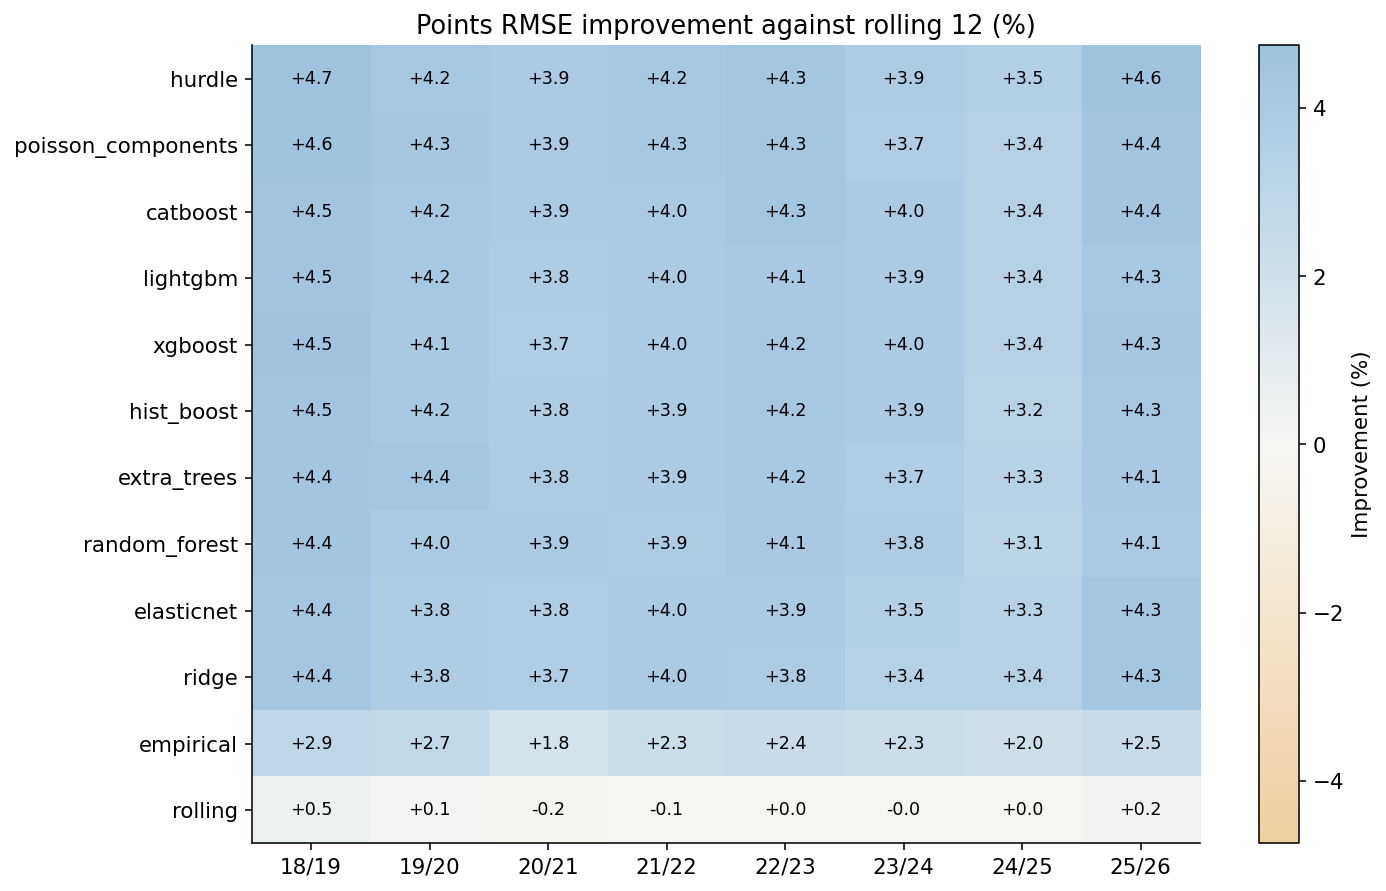

In [3]:
families=pd.read_csv(base/'family-comparison.csv')
raw=json.loads((base/'nested-scores.json').read_text())
rolling={r['year']:r['active']['rmse'] for r in raw if r['model']=='rolling12'}
families['gain']=families.apply(lambda r:100*(rolling[r['year']]-r['rmse'])/rolling[r['year']],axis=1)
pivot=families.pivot(index='family',columns='year',values='gain')
pivot=pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]
from matplotlib.colors import LinearSegmentedColormap,TwoSlopeNorm
cmap=LinearSegmentedColormap.from_list('gain',['#f0cf9e','#f6f6f3','#9dc3df'])
limit=max(1,float(np.abs(pivot.to_numpy()).max()))
fig,ax=plt.subplots(figsize=(10.5,6.5))
image=ax.imshow(pivot.to_numpy(),aspect='auto',cmap=cmap,norm=TwoSlopeNorm(vmin=-limit,vcenter=0,vmax=limit))
ax.set_xticks(range(len(pivot.columns)),[f'{y%100:02d}/{(y+1)%100:02d}' for y in pivot.columns])
ax.set_yticks(range(len(pivot.index)),pivot.index)
for i in range(len(pivot)):
 for j in range(len(pivot.columns)):
  ax.text(j,i,f'{pivot.iloc[i,j]:+.1f}',ha='center',va='center',fontsize=9,color='black')
ax.grid(False);ax.set_title('Points RMSE improvement against rolling 12 (%)')
fig.colorbar(image,ax=ax,label='Improvement (%)');fig.tight_layout()
plt.show()

### 3. Compare with the existing v1 on identical recent cases

All methods use exactly the existing v1 evaluation cases. These exclude DGWs and first-observed rows because the old benchmark did. The broad outer tests above include them.

period                    2023-24  2024-25  2025-26
label                                              
Exact Poisson components   2.9655   2.8811   2.9967
Live v1                    3.0228   2.9206   3.0678
Nested ensemble            2.9638   2.8819   2.9962
V1 + boosted minutes       2.9878   2.8950   3.0029
V1 + calibrated minutes    2.9884   2.8954   3.0033


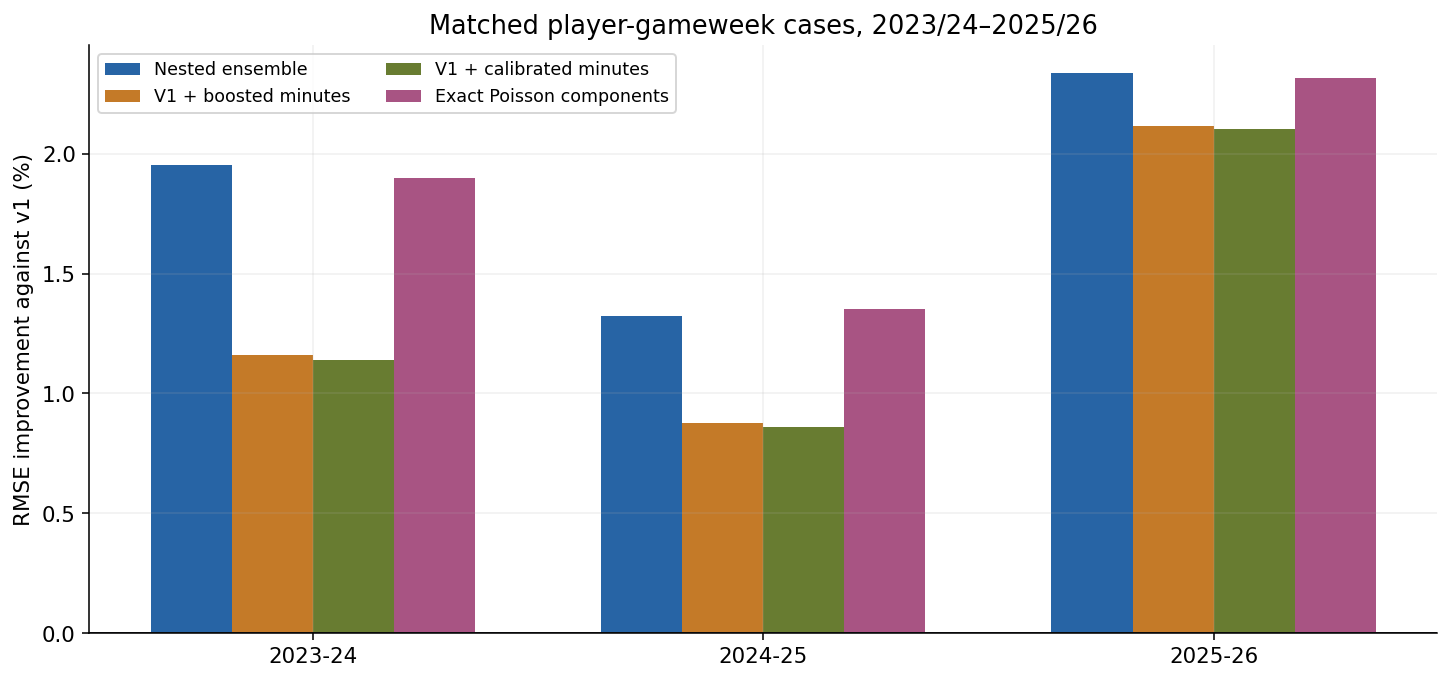

In [4]:
recent=comparison[comparison.pool=='matched_modern']
methods=['nested_ensemble','v1_new_minutes_raw','v1_new_minutes_calibrated','exact_components_selected']
pivot=recent[recent.model.isin(methods)].pivot(index='period',columns='model',values='improvement_vs_v1_percent')[methods]
fig,ax=plt.subplots(figsize=(10.5,5))
x=np.arange(len(pivot));width=.18
for j,m in enumerate(methods): ax.bar(x+(j-1.5)*width,pivot[m],width,label=labels[m],color=colors[m])
ax.axhline(0,color='#25282d',linewidth=1);ax.set_xticks(x,pivot.index)
ax.set_ylabel('RMSE improvement against v1 (%)');ax.set_title('Matched player-gameweek cases, 2023/24–2025/26')
ax.legend(ncol=2,fontsize=9);fig.tight_layout();plt.show()
print(recent[recent.model.isin(['v1']+methods)].pivot(index='label',columns='period',values='rmse').round(4).to_string())

### 4. Inspect the seven current gameweeks

The fixed v1 candidate pool contains 1,205 player-gameweek predictions; owned squads contain 105. These seven outcomes did not fit or select a configuration. They were already known when the research was designed, and provide limited independent week-level evidence.

                   label    n   rmse    mae  bias_forecast_minus_actual  improvement_vs_v1_percent
                 Live v1 1205 3.1865 2.3335                     -0.3011                     0.0000
         Nested ensemble 1205 3.1895 2.3467                     -0.2590                    -0.0945
    V1 + boosted minutes 1205 3.1718 2.3588                     -0.1551                     0.4624
 V1 + calibrated minutes 1205 3.1698 2.3669                     -0.1235                     0.5239
Exact Poisson components 1205 3.1928 2.3584                     -0.2504                    -0.1981


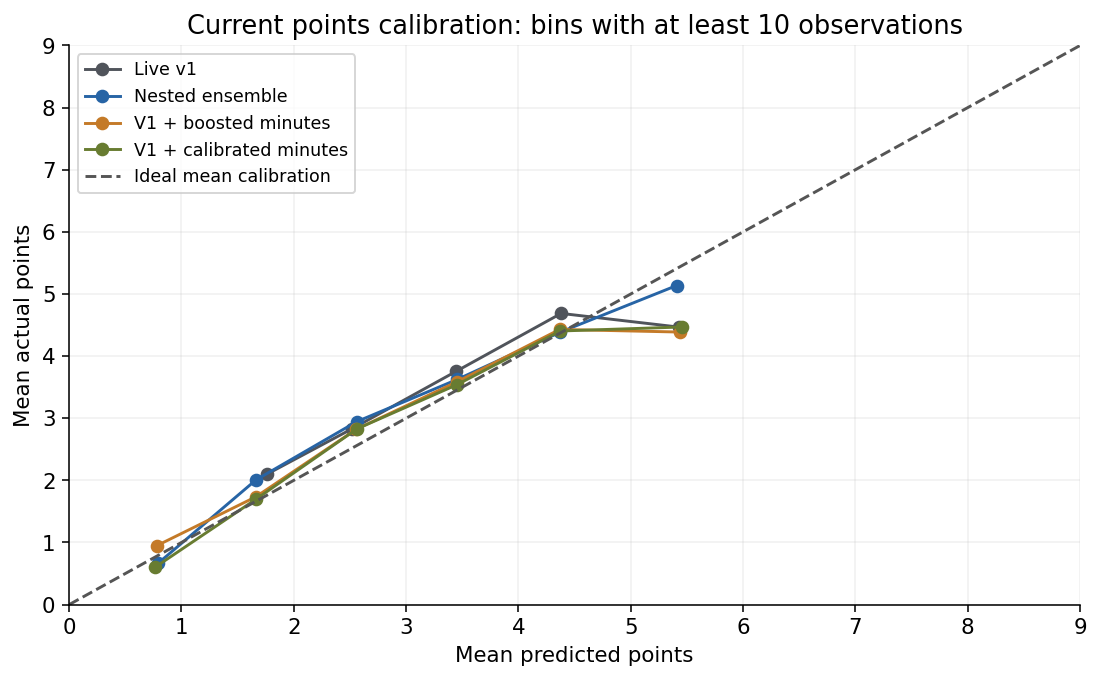

In [5]:
now=comparison[(comparison.pool=='fixed_candidates')&(comparison.model.isin(['v1','nested_ensemble','v1_new_minutes_raw','v1_new_minutes_calibrated','exact_components_selected']))]
print(now[['label','n','rmse','mae','bias_forecast_minus_actual','improvement_vs_v1_percent']].round(4).to_string(index=False))
current=pd.read_csv(base/'extended-current-predictions.csv.gz');active=current[current.likely_player==1]
fig,ax=plt.subplots(figsize=(8,5))
for m in ['v1','nested_ensemble','v1_new_minutes_raw','v1_new_minutes_calibrated']:
 tmp=active.assign(band=pd.cut(active[m],[-np.inf,1,2,3,4,5,6,8,np.inf]))
 bins=tmp.groupby('band',observed=True).agg(pred=(m,'mean'),actual=('y_total_points','mean'),n=('gw','size'))
 bins=bins[bins.n>=10];ax.plot(bins.pred,bins.actual,marker='o',label=labels[m],color=colors[m])
ax.plot([0,9],[0,9],'--',color='#555555',label='Ideal mean calibration')
ax.set(xlim=(0,9),ylim=(0,9),xlabel='Mean predicted points',ylabel='Mean actual points',title='Current points calibration: bins with at least 10 observations')
ax.legend(fontsize=9);fig.tight_layout();plt.show()

### 5. Inspect appearance and ≥60-minute probabilities

Disjoint state probabilities are calibrated on prior OOF cases, then captured availability flags are applied. A good average probability does not by itself establish good individual forecasts.

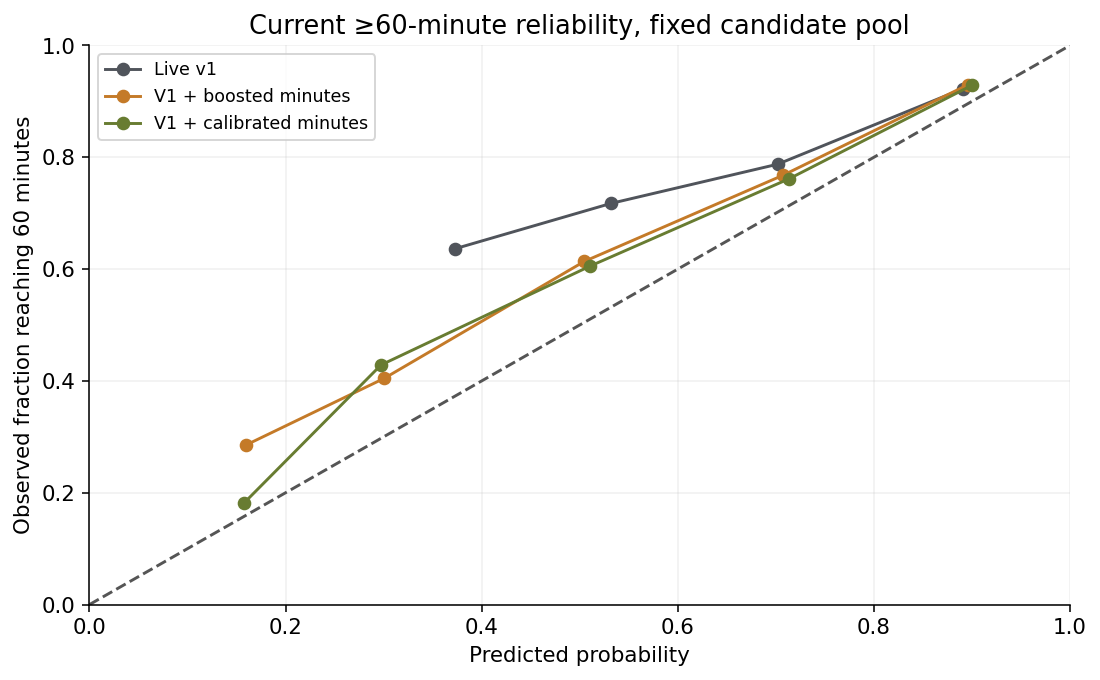

In [6]:
fig,ax=plt.subplots(figsize=(8,5))
frames={'v1':pd.read_csv(base/'v1-new-minutes-current-raw.csv'),'v1_new_minutes_raw':pd.read_csv(base/'v1-new-minutes-current-raw.csv'),'v1_new_minutes_calibrated':pd.read_csv(base/'v1-new-minutes-current-calibrated.csv')}
base_pred=pd.read_csv(base/'extended-current-predictions.csv.gz')
frames['v1']=base_pred.copy();frames['v1']['p60']=frames['v1']['v1_p60'];frames['v1']['actual_minutes']=frames['v1']['y_minutes']
for name,f in frames.items():
 f=f[f.likely_player==1].copy();f['actual_long']=(f.actual_minutes>=60).astype(int)
 f['band']=pd.cut(f.p60,np.linspace(0,1.000001,6),include_lowest=True)
 b=f.groupby('band',observed=True).agg(pred=('p60','mean'),actual=('actual_long','mean'),n=('gw','size'))
 ax.plot(b.pred,b.actual,marker='o',label=labels[name],color=colors[name])
ax.plot([0,1],[0,1],'--',color='#555555');ax.set(xlim=(0,1),ylim=(0,1),xlabel='Predicted probability',ylabel='Observed fraction reaching 60 minutes',title='Current ≥60-minute reliability, fixed candidate pool')
ax.legend(fontsize=9);fig.tight_layout();plt.show()

### 6. Inspect conditional squad decisions

These are legal XI/captain/bench choices on the actual owned 15 with actual autosubs. They are not a transfer, wildcard or season-rank backtest.

                  model  points  difference_from_actual
        Nested ensemble   429.0                    14.0
                Live v1   422.0                     7.0
   V1 + boosted minutes   422.0                     7.0
V1 + calibrated minutes   422.0                     7.0


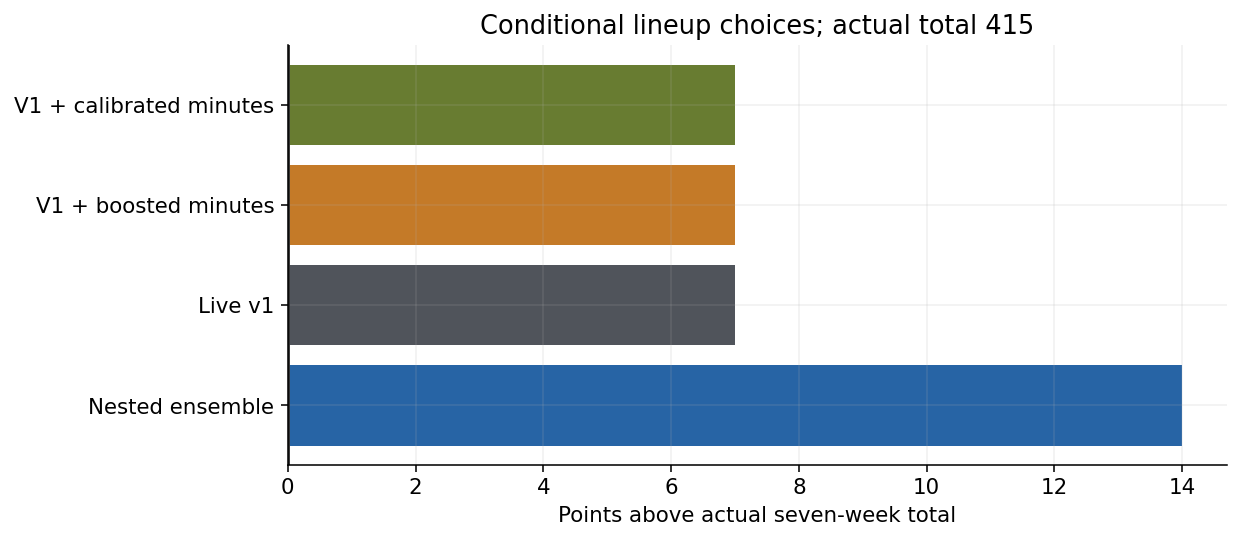

In [7]:
lineups=json.loads((base/'lineup-assessment.json').read_text())
hybrids=json.loads((base/'v1-new-minutes-current.json').read_text())
totals={m:v for m,v in lineups['totals'].items() if m in ['v1','nested_ensemble']}
for key,v in hybrids.items():totals['v1_new_minutes_'+key]=v['conditional_squad_score']
actual=lineups['actual_points']
print(pd.DataFrame([{'model':labels[k],'points':v,'difference_from_actual':v-actual} for k,v in totals.items()]).to_string(index=False))
fig,ax=plt.subplots(figsize=(9,4))
names=list(totals);delta=[totals[n]-actual for n in names]
ax.barh([labels[n] for n in names],delta,color=[colors[n] for n in names]);ax.axvline(0,color='#333333')
ax.set_xlabel('Points above actual seven-week total');ax.set_title(f'Conditional lineup choices; actual total {actual:g}')
fig.tight_layout();plt.show()

### 7. Test six-gameweek forecasts

All player features are frozen at the origin. Targets that cross season boundaries or have unknown future coverage are excluded. Realised fixture counts are an oracle schedule assumption. The uncertainty procedure uses eight-GW blocks because six-week labels overlap.

{
  "rows": 58464,
  "seasons": 8,
  "gameweeks": 263,
  "rmse_improvement_percent": 8.68720677493139,
  "interval_95_percent": [
    7.470623978855375,
    9.837423793195667
  ],
  "draws": 2000,
  "block_length": 8,
  "caveat": "Conditional on the retrospective protocol and available archive population; not a guarantee against future regime or selection effects."
}


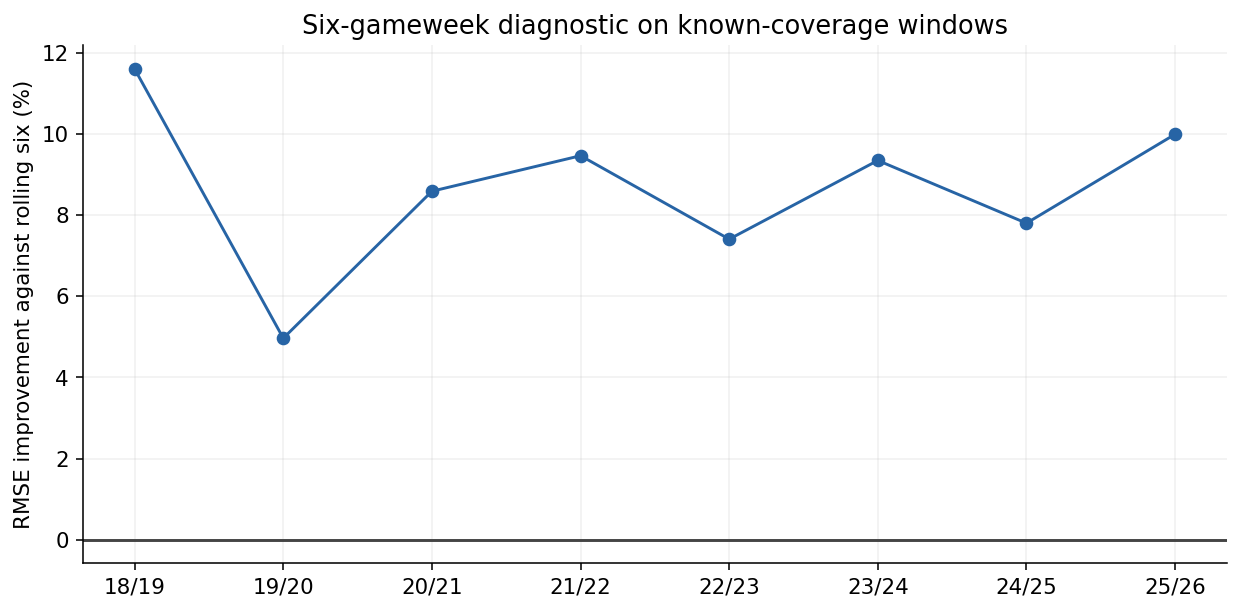

In [8]:
six=json.loads((base/'six-week-assessment.json').read_text())
s=pd.DataFrame(six['scores']);p=s[s.year<2026].pivot(index='year',columns='model',values='rmse')
gain=(p.rolling_six-p.selected_six)/p.rolling_six*100
fig,ax=plt.subplots(figsize=(9,4.5));ax.plot(gain.index,gain,marker='o',color='#2764a5')
ax.axhline(0,color='#444444');ax.set_xticks(gain.index,[f'{v%100:02d}/{(v+1)%100:02d}' for v in gain.index])
ax.set_ylabel('RMSE improvement against rolling six (%)');ax.set_title('Six-gameweek diagnostic on known-coverage windows');fig.tight_layout();plt.show()
print(json.dumps(six['uncertainty'],indent=2))

## Takeaways

Choose a procedure from historical evidence and confirm it prospectively. Assess RMSE, MAE, probability calibration, cold starts and decisions together. Keep sourced role/news overrides and preserve the Claude playbook entry points. Research artifacts are not a drop-in production replacement. See REPORT.md for comparisons, uncertainty and the promotion recommendation.